# Scenario weights for grid expansion delays (NEP panel)

Same model as `build_probabilites_from_delay_data.ipynb` (read its context section first; its settled design
decisions still hold). Only the delay, cancellation and correlation inputs change. They now come from the NEP
panel (all NEP and implementation reports 2012-2025, one row per line and report), estimated in
`nep_panel_delay_explorer.ipynb` and stored in `data/pypsa-de/grid_delay/nep_panel/`.

| Input | Old builder | This builder |
|---|---|---|
| Delay distribution | one pooled BNetzA histogram (105 projects, read off plots) | one per status (confirmed, in permitting, under construction), censoring-aware (Turnbull), 312 lines |
| Cancellation | TYNDP Europe: 0.13 (construction), 0.32 AC, 0.14 DC | NEP life table: 0.088 confirmed, 0.048 permitting, 0 construction |
| Correlation | `DELAY_CORRELATION` set by hand (0.03) | period 0.17 (all projects), 0.54 within one NEP project (target slips) |
| Early completion | not possible; projects after 2035 dropped | negative delays possible; projects after 2035 stay in |

The delay D of a project is drawn from the distribution of its status:
D = commissioning year minus the target year of a report in which a line had this status, for reports at least
3 years before the target. Mass that the data cannot place (still open later than any observed line) is D = inf:
such a project is not in the 2035 grid.

Correlation: z = sqrt(rho_p) Z + sqrt(rho_j - rho_p) Z_project + sqrt(1 - rho_j) e, with Z shared by all projects
in a draw, Z_project shared by the measures of one NEP project (`NEP_P302_M511` -> `P302`), and e per project.
Each delay is the quantile of its status distribution at Phi(z).

In [57]:
import hashlib
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa
import yaml
from scipy.stats import norm

BASE_YEAR = 2025
HORIZON = 2035
SCENARIO_YEARS = list(range(BASE_YEAR, HORIZON + 1, 1)) # [2025, 2027, 2029, 2031, 2033, 2035]
N_DRAWS = 100000
SEED = 0
# NEP panel inputs, written by nep_panel_delay_explorer.ipynb
NEP_PANEL = Path.cwd().parent / "data" / "pypsa-de" / "grid_delay" / "nep_panel"
PROJECT_CORRELATION = True  # measures of one NEP project share an extra common factor

# merged over config/config.de.yaml for build_transmission_projects
TP_CONFIG = """
transmission_projects:
  enable: true
  include:
    manual: false # original data (unclear)
    nep: false # is NEP 2023 but incomplete (original data)
    nep2023confirmed: true
    nep2025draft: false
    tyndp2020: false # original data
    tyndp2022confirmed: true
    tyndp2024draft: false
    tyndp2026draft: false # release is planned for Dec 2026
  skip: [] # skip nothing
  # skip:
  # - upgraded_lines
  # - upgraded_links
  status:
  # - under_consideration
  # - planned_not_yet_permitting
  - confirmed
  - in_permitting
  - under_construction
  # - commissioned
  new_link_capacity: keep #keep or zero
  overlap_decisions: data/transmission_projects/overlap_decisions.csv
"""
# run providing base network and shapes; only build_transmission_projects is rerun
SOURCE_RUN = "20261027-NUTS2-365h-2025EXO-2030EXO-2035EXO-10-50-40-new-plots"
SCENARIO = "KN2045_Bal_v5_abroad_capa_freeze"

rng = np.random.default_rng(SEED)

## 1. Delay distribution per status

Probability per delay value from `delay_pmf.csv`; `inf` = not commissioned within any observed delay.

In [58]:
pmf = pd.read_csv(NEP_PANEL / "delay_pmf.csv").groupby("status")
PMF = {s: g.set_index("delay").probability for s, g in pmf}
CANCEL = pd.read_csv(NEP_PANEL / "cancel_rate.csv", index_col="status").p_cancel
RHO = pd.read_csv(NEP_PANEL / "delay_correlation.csv", index_col="level")
rho_p = RHO.rho["period"]
rho_j = RHO.rho["project"] if PROJECT_CORRELATION else rho_p

thresholds = np.arange(0, 15)
survival = pd.DataFrame({s: [p[p.index > t].sum() for t in thresholds] for s, p in PMF.items()}, index=thresholds)
survival.index.name = "t [a]"
print(f"cancellation: {CANCEL.round(3).to_dict()}")
print(f"correlation: period {rho_p:.3f}, project {rho_j:.3f}")
survival.round(3).rename(columns=lambda s: f"P(D > t | {s})")

cancellation: {'confirmed': 0.088, 'in_permitting': 0.048, 'under_construction': 0.0}
correlation: period 0.174, project 0.535


,P(D > t | confirmed),P(D > t | in_permitting),P(D > t | under_construction)
t [a],,,
0,0.901,0.835,0.610
1,0.852,0.688,0.466
2,0.766,0.583,0.388
3,0.671,0.472,0.388
4,0.500,0.439,0.278
5,0.406,0.367,0.278
6,0.377,0.244,0.278
7,0.362,0.184,0.000
8,0.326,0.138,0.000


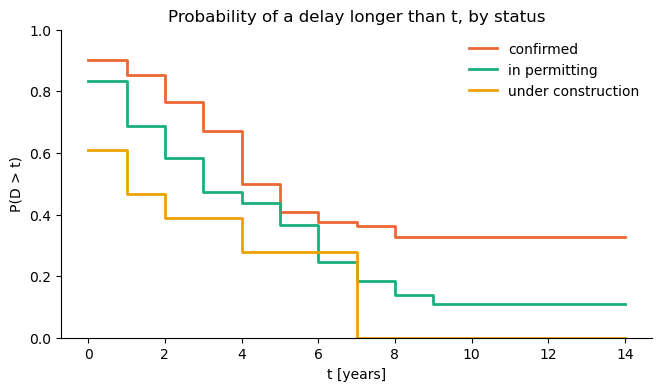

In [59]:
colours = {"confirmed": "#eb6834", "in_permitting": "#1baf7a", "under_construction": "#eda100"}
fig, ax = plt.subplots(figsize=(6.5, 3.8), layout="constrained")
for s, p in PMF.items():
    ax.step(survival.index, survival[s], where="post", color=colours[s], lw=2, label=s.replace("_", " "))
ax.set(xlabel="t [years]", ylabel="P(D > t)", ylim=(0, 1), title="Probability of a delay longer than t, by status")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 2. Transmission projects and their capacity

Projects come from the processed output of `build_transmission_projects` (plans and statuses from `TP_CONFIG`,
duplicates resolved by the pipeline). Only branches with at least one end in Germany are kept.

Capacity in TWkm: DC links use `p_nom * length`, new AC lines `s_nom * length`. An upgrade adds only
`(s_nom - s_nom of the replaced branch) * length`; the replaced branch is the base-network line or an earlier
upgrade stage. A project can span several model branches; they share one `project_id`.

In [60]:
repo = Path.cwd().parent
tp = yaml.safe_load(TP_CONFIG)["transmission_projects"]
prefix = "tp-" + hashlib.sha1(json.dumps(tp).encode()).hexdigest()[:8]
run_dir = repo / "resources" / prefix / SCENARIO
proj_dir = run_dir / "transmission_projects"

if not (proj_dir / "new_lines.csv").exists():
    source = repo / "resources" / SOURCE_RUN / SCENARIO
    for fn in ["networks/base.nc", "offshore_shapes.geojson", "europe_shape.geojson"]:
        (run_dir / fn).parent.mkdir(parents=True, exist_ok=True)
        (run_dir / fn).unlink(missing_ok=True)
        (run_dir / fn).symlink_to(source / fn)
    override = run_dir / "transmission_projects_config.yaml"
    override.write_text(
        yaml.safe_dump({"run": {"prefix": prefix, "name": [SCENARIO]}, "transmission_projects": tp}, sort_keys=False)
    )
    target = (proj_dir / "new_lines.csv").relative_to(repo)
    subprocess.run(
        [sys.executable, "-m", "snakemake", str(target), "--configfile", str(override), "-c1",
         "--allowed-rules", "build_transmission_projects", "--rerun-triggers", "mtime"],
        cwd=repo,
        check=True,
    )

print(f"transmission projects from {proj_dir.relative_to(repo)}")

transmission projects from resources/tp-7a8d3334/KN2045_Bal_v5_abroad_capa_freeze/transmission_projects


In [61]:
n = pypsa.Network(run_dir / "networks" / "base.nc")
lines = pd.read_csv(proj_dir / "new_lines.csv", index_col=0)
links = pd.read_csv(proj_dir / "new_links.csv", index_col=0)
new_buses = pd.read_csv(proj_dir / "new_buses.csv", index_col=0)

# the pipeline writes column-less files when no buses are added or upgrades are skipped
country = n.buses.country
if not new_buses.empty:
    country = pd.concat([country, new_buses.country])
if "replaced_asset" not in lines:
    lines["replaced_asset"] = np.nan


def touches_de(branches):
    return country.loc[branches.bus0].eq("DE").to_numpy() | country.loc[branches.bus1].eq("DE").to_numpy()


upgrade = lines.replaced_asset.notna()
s_nom = pd.concat([n.lines.s_nom, lines.s_nom])
s_nom_old = pd.Series(0.0, index=lines.index)
s_nom_old[upgrade] = s_nom.loc[lines.replaced_asset[upgrade]].to_numpy()
added = lines.s_nom - s_nom_old
print(f"{(added < 0).sum()} upgrades lower s_nom, counted as 0")

lines_cap = pd.DataFrame(
    {
        "project_id": lines["project_id"],
        "status": lines["project_status"],
        "build_year": lines["build_year"].astype(int),
        "twkm": added.clip(lower=0) * lines["length"] / 1e6,
        "kind": np.where(upgrade, "AC upgrade", "AC"),
    }
)[touches_de(lines)]
links_cap = pd.DataFrame(
    {
        "project_id": links["project_id"],
        "status": links["project_status"],
        "build_year": links["build_year"].astype(int),
        "twkm": links["p_nom"] * links["length"] / 1e6,
        "kind": "DC",
    }
)[touches_de(links)]

projects = pd.concat([links_cap, lines_cap])
projects.index.name = "branch"

print(f"{projects.project_id.nunique()} projects on {len(projects)} branches, {projects.twkm.sum():.1f} TWkm total")
projects.groupby(["kind", "build_year"]).twkm.agg(["count", "sum"]).round(2)

INFO:pypsa.network.io:New version 1.4.0 available! (Current: 1.2.4)
INFO:pypsa.network.io:Imported network 'PyPSA-Eur (osm vlatest)' has buses, carriers, lines, links, shapes, transformers


19 upgrades lower s_nom, counted as 0
203 projects on 287 branches, 40.4 TWkm total


count   sum
kind       build_year             
AC         2026            2  0.14
           2027            5  0.54
           2029            4  0.76
           2030            1  0.12
           2031            2  0.46
           2032            5  1.66
           2033            2  0.13
           2034            2  0.12
           2035            3  0.89
           2037           17  3.79
           2038            1  0.06
           2045            3  2.44
AC upgrade 0               1  0.02
           2026           17  1.26
           2027           11  0.81
           2028           11  1.18
           2029           11  0.66
           2030           22  1.33
           2031           32  1.61
           2032           14  1.52
           2033           22  0.85
           2034            4  0.29
           2035           25  0.69
           2036            4  0.39
           2037           39  2.85
           2038            3  0.63
           2045            6  1.02
DC         2026            1  0.68
           2027            2  1.67
           2028            3  3.48
           2032            3  2.48
           2033            2  1.93
           2034            1  0.34
           2035            1  0.92
           2037            2  1.53
           2038            1  0.02
           2040            1  1.06
           2045            1  0.10

In [62]:
baseline = projects[projects.build_year <= BASE_YEAR]
stochastic = projects[projects.build_year > BASE_YEAR].copy()  # after 2035 too: early completion is possible
cap_base = baseline.twkm.sum()

print(f"baseline (planned <= {BASE_YEAR}): {baseline.project_id.nunique():3d} projects, {cap_base:6.1f} TWkm")
for label, part in stochastic.groupby(stochastic.build_year > HORIZON):
    span = f"after {HORIZON}" if label else f"{BASE_YEAR + 1}-{HORIZON}"
    print(f"stochastic {span}: {part.project_id.nunique():3d} projects, {part.twkm.sum():6.1f} TWkm")
pd.crosstab(stochastic.drop_duplicates("project_id").status, stochastic.drop_duplicates("project_id").kind)

baseline (planned <= 2025):   1 projects,    0.0 TWkm
stochastic 2026-2035: 141 projects,   26.5 TWkm
stochastic after 2035:  61 projects,   13.9 TWkm


kind,AC,AC upgrade,DC
status,,,
confirmed,33,81,3
in_permitting,13,43,9
under_construction,1,13,6


## 3. Scenario capacities

The "year-$y$ grid" contains all projects planned for completion up to $y$.

In [63]:
scenario_cap = pd.Series(
    {year: projects.loc[projects.build_year <= year, "twkm"].sum() for year in SCENARIO_YEARS},
    name="Cap [TWkm]",
)
scenario_cap.index.name = "grid year"
scenario_cap.round(2).to_frame()

,Cap [TWkm]
grid year,
2025,0.02
2026,2.10
2027,5.12
2028,9.79
2029,11.21
2030,12.66
2031,14.73
2032,20.40
2033,23.30


In [64]:
caps = scenario_cap.to_numpy()
# bin edges halfway between neighbouring scenario capacities, outer edges open
edges = np.concatenate([[-np.inf], (caps[:-1] + caps[1:]) / 2, [np.inf]])

pd.DataFrame(
    {"lower": edges[:-1], "Cap": caps, "upper": edges[1:]}, index=scenario_cap.index
).round(2)

,lower,Cap,upper
grid year,,,
2025,-inf,0.02,1.06
2026,1.06,2.10,3.61
2027,3.61,5.12,7.46
2028,7.46,9.79,10.50
2029,10.50,11.21,11.94
2030,11.94,12.66,13.70
2031,13.70,14.73,17.56
2032,17.56,20.40,21.85
2033,21.85,23.30,23.68


## 4. Monte Carlo

One experiment: draw a delay for every stochastic project from the distribution of its status, linked by the
two-level copula; add it to the planned year; keep the projects that finish by 2035 and are not cancelled; sum
their capacity; assign the sum to a scenario bin. All branches of one project share its delay and cancellation.
Cancellation is independent of delay and of other projects.

In [65]:
project_status = stochastic.groupby("project_id").status.agg(["first", "nunique"])
assert (project_status["nunique"] == 1).all(), "branches of one project differ in status"
project_status = project_status["first"]
assert project_status.isin(PMF).all(), f"no delay distribution for {set(project_status) - set(PMF)}"
project = project_status.index.get_indexer(stochastic.project_id)  # branch -> project
ids = project_status.index.to_series()
group, _ = pd.factorize(ids.str.split("_").str[1].where(ids.str.startswith("NEP_"), ids))  # NEP project, else own
build_year = stochastic.build_year.to_numpy()
twkm = stochastic.twkm.to_numpy()
cancel_p = project_status.map(CANCEL).to_numpy()


def quantile(p: pd.Series, u: np.ndarray) -> np.ndarray:
    """Delay at probability level u of a distribution given as probability per delay."""
    c = p.cumsum().to_numpy()
    return p.index.to_numpy()[np.minimum(np.searchsorted(c, u), c.size - 1)]


def simulate(rho_p: float, rho_j: float, seed: int = SEED) -> tuple[pd.Series, np.ndarray]:
    """Scenario weights and realized capacities for one correlation setting."""
    rng = np.random.default_rng(seed)
    shape = (N_DRAWS, project_status.size)
    z = (np.sqrt(rho_p) * rng.standard_normal((N_DRAWS, 1))
         + np.sqrt(rho_j - rho_p) * rng.standard_normal((N_DRAWS, group.max() + 1))[:, group]
         + np.sqrt(1 - rho_j) * rng.standard_normal(shape))
    u = norm.cdf(z)
    delays = np.empty(shape)
    for s, p in PMF.items():
        m = (project_status == s).to_numpy()
        delays[:, m] = quantile(p, u[:, m])
    cancelled = rng.random(shape) < cancel_p
    available = ((build_year + delays[:, project]) <= HORIZON) & ~cancelled[:, project]
    cap = cap_base + available @ twkm
    counts = np.bincount(np.digitize(cap, edges[1:-1]), minlength=len(SCENARIO_YEARS))
    return pd.Series(counts / N_DRAWS, index=scenario_cap.index, name="probability"), cap


weights, realized_cap = simulate(rho_p, rho_j)
result = pd.concat([scenario_cap.round(2), weights.round(4)], axis=1)
result["delay [a]"] = HORIZON - result.index
print(f"sum of weights: {weights.sum():.4f}")
result

sum of weights: 1.0000


,Cap [TWkm],probability,delay [a]
grid year,,,
2025,0.02,0.0000,10
2026,2.10,0.0000,9
2027,5.12,0.0000,8
2028,9.79,0.0191,7
2029,11.21,0.0533,6
2030,12.66,0.1326,5
2031,14.73,0.4416,4
2032,20.40,0.3051,3
2033,23.30,0.0348,2


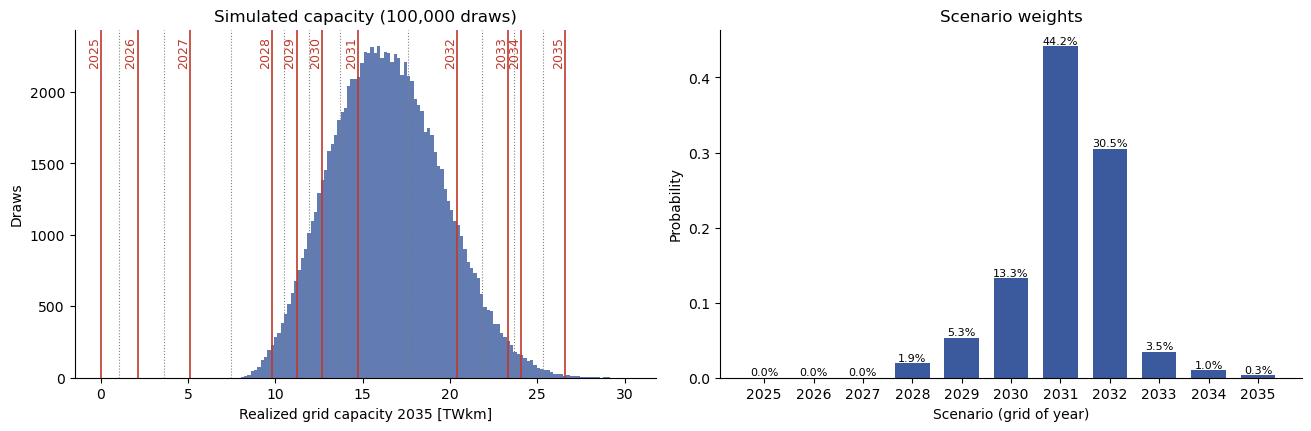

In [66]:
fig, axs = plt.subplot_mosaic([["cap", "weights"]], figsize=(13, 4.2), layout="constrained")
ax = axs["cap"]
ax.hist(realized_cap, bins=120, color="#3b5a9d", alpha=0.8)
for year, cap in scenario_cap.items():
    ax.axvline(cap, color="#c0392b", lw=1.2)
    ax.text(cap, 0.98, str(year), rotation=90, ha="right", va="top", color="#c0392b", fontsize=9,
            transform=ax.get_xaxis_transform())
for edge in edges[1:-1]:
    ax.axvline(edge, color="grey", lw=0.8, ls=":")
ax.set(xlabel="Realized grid capacity 2035 [TWkm]", ylabel="Draws", title=f"Simulated capacity ({N_DRAWS:,} draws)")

ax = axs["weights"]
x = np.arange(len(SCENARIO_YEARS))
ax.bar(x, weights.to_numpy(), color="#3b5a9d", width=0.7)
for i, value in enumerate(weights.to_numpy()):
    ax.text(i, value, f"{value:.1%}", ha="center", va="bottom", fontsize=8)
ax.set(xticks=x, xticklabels=SCENARIO_YEARS, xlabel="Scenario (grid of year)", ylabel="Probability",
       title="Scenario weights")
for ax in axs.values():
    ax.spines[["top", "right"]].set_visible(False)
plt.show()

## 5. Exact cross-check

With independent projects, the capacity distribution can be convolved exactly, project by project over all its
delays. Monte Carlo with both correlations set to 0 must agree up to sampling noise (about +-0.002).

In [67]:
resolution = 1e-3  # TWkm grid
grid_cap = np.rint(twkm / resolution).astype(int)

pmf_cap = np.zeros(grid_cap.sum() + 1)
pmf_cap[0] = 1.0
for i, s in enumerate(project_status):
    in_project = project == i
    convolved = cancel_p[i] * pmf_cap
    for delay, prob in PMF[s].items():
        step = grid_cap[in_project & (build_year + delay <= HORIZON)].sum()
        convolved[step:] += (1 - cancel_p[i]) * prob * pmf_cap[: pmf_cap.size - step]
    pmf_cap = convolved

support = cap_base + np.arange(pmf_cap.size) * resolution
exact = pd.Series(np.bincount(np.digitize(support, edges[1:-1]), weights=pmf_cap, minlength=len(SCENARIO_YEARS)),
                  index=scenario_cap.index)
independent, _ = simulate(0.0, 0.0)
check = pd.concat({"monte carlo, independent": independent, "exact, independent": exact}, axis=1)
assert (check.diff(axis=1).iloc[:, 1].abs() < 0.01).all(), "Monte Carlo and exact convolution disagree"
check.round(4).T

grid year,2025,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035
"monte carlo, independent",0.0,0.0,0.0,0.0,0.0002,0.0263,0.7542,0.2193,0.0000,0.0,0.0
"exact, independent",0.0,0.0,0.0,0.0,0.0002,0.0259,0.7570,0.2169,0.0001,0.0,0.0


## 6. Sensitivity and comparison with the old builder

Weights for the correlation estimate and its 90 % interval (period level), without the project level, fully
independent, and the old builder's result (`grid_delay_scenario_weights.csv`, BNetzA histogram, TYNDP cancellation,
rho = 0.03). In the figure, vertical lines span the weights over the 90 % interval of the period correlation.

In [68]:
runs = {
    "independent": (0.0, 0.0),
    f"period {RHO.lo['period']:.2f} (90 % low)": (RHO.lo["period"], max(RHO.lo["period"], rho_j)),
    f"period {rho_p:.2f}, no project level": (rho_p, rho_p),
    f"period {rho_p:.2f}, project {rho_j:.2f} (main)": (rho_p, rho_j),
    f"period {RHO.hi['period']:.2f} (90 % high)": (RHO.hi["period"], max(RHO.hi["period"], rho_j)),
}
sens = pd.DataFrame({name: simulate(*r)[0] for name, r in runs.items()})
sens["old builder"] = pd.read_csv("grid_delay_scenario_weights.csv", index_col=0).probability
mean_slip = (sens.mul(HORIZON - sens.index, axis=0)).sum().rename("expected programme slip [a]")
pd.concat([sens.T.round(3), mean_slip.round(2)], axis=1)

,2025,2026,2027,2028,2029,2030,2031,2032,2033,2034,2035,expected programme slip [a]
independent,0.0,0.0,0.000,0.000,0.000,0.026,0.754,0.219,0.000,0.000,0.000,3.81
period 0.02 (90 % low),0.0,0.0,0.000,0.000,0.003,0.062,0.668,0.264,0.002,0.000,0.000,3.80
"period 0.17, no project level",0.0,0.0,0.000,0.019,0.052,0.133,0.444,0.305,0.034,0.010,0.003,3.88
"period 0.17, project 0.53 (main)",0.0,0.0,0.000,0.019,0.053,0.133,0.442,0.305,0.035,0.010,0.003,3.88
period 0.27 (90 % high),0.0,0.0,0.000,0.046,0.073,0.135,0.372,0.291,0.052,0.020,0.011,3.92
old builder,0.0,0.0,0.037,0.659,0.000,0.000,0.000,0.000,0.000,0.113,0.191,5.02


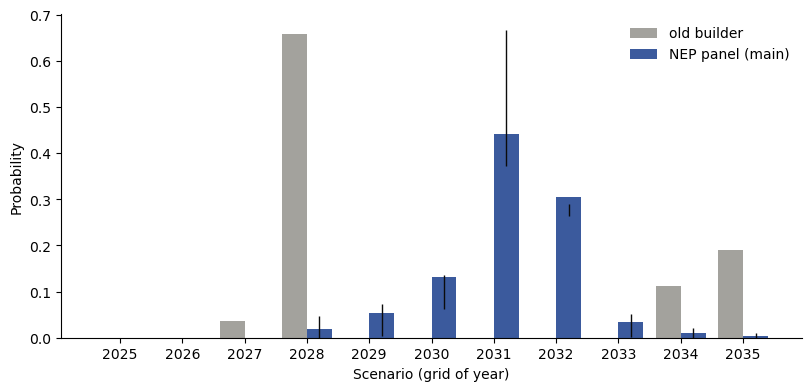

In [69]:
fig, ax = plt.subplots(figsize=(8, 3.8), layout="constrained")
x = np.arange(len(SCENARIO_YEARS))
main = f"period {rho_p:.2f}, project {rho_j:.2f} (main)"
ax.bar(x - 0.2, sens["old builder"], width=0.4, color="#a3a29d", label="old builder")
ax.bar(x + 0.2, sens[main], width=0.4, color="#3b5a9d", label="NEP panel (main)")
lo_name, hi_name = list(runs)[1], list(runs)[-1]
ax.vlines(x + 0.2, sens[[lo_name, hi_name]].min(axis=1), sens[[lo_name, hi_name]].max(axis=1), color="#0b0b0b", lw=1)
ax.set(xticks=x, xticklabels=SCENARIO_YEARS, xlabel="Scenario (grid of year)", ylabel="Probability")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

In [70]:
result.to_csv("grid_delay_scenario_weights_nep_panel.csv")
result

,Cap [TWkm],probability,delay [a]
grid year,,,
2025,0.02,0.0000,10
2026,2.10,0.0000,9
2027,5.12,0.0000,8
2028,9.79,0.0191,7
2029,11.21,0.0533,6
2030,12.66,0.1326,5
2031,14.73,0.4416,4
2032,20.40,0.3051,3
2033,23.30,0.0348,2


## Assumptions

- **Status at NEP 2023.** A project's delay distribution is the one of its NEP 2023 status. Later reports (NEP
  2025) know more about some projects; they are not used here.
- **Delay is measured against one report's target**, for reports at least 3 years before the target. Pooled over
  2012-2025; a stable delay process is assumed. TYNDP 2022 projects (cross-border) use the same distributions.
- **Censoring-aware, not optimistic.** Lines still open count with what is known (not done by March 2026). Mass the
  data cannot place counts as "not by 2035".
- **Correlation from target slips.** rho is the intra-class correlation of normal scores of target slips per NEP
  period (8 periods, wide interval); part of it may be reporting practice. Measures of one NEP project share an
  extra factor; TYNDP projects only the period factor.
- **Cancellation** is the NEP life-table probability per status, independent of delay and of other projects. 0 for
  construction rests on 67 lines that left that phase.
- Delay does not depend on project size or technology (DC samples are too small); capacity matching as before.